## **TP ERP OddBall sEEG (Dr S.Lagarde - Dr N.Catz)**
M1 Neurosciences 2026-2027

Please find the data https://amubox.univ-amu.fr/s/8JaRcqQkPSajNA7


In [9]:
import numpy as np
import matplotlib.pyplot as plt
import os

notch_freq  = 50          # Hz  (fréquence secteur)
band_low    = 0.3         # Hz  (passe-bande bas)
band_high   = 30          # Hz  (passe-bande haut)
samp_freq     = 512         # Hz  (fréquence d'échantillonnage)

tmin        = -0.2        # s  (début époque par rapport au stimulus)
tmax        =  0.8        # s  (fin époque)
baseline    = (-0.2, 0)   # fenêtre de baseline (s)


print(os.getcwd())
os.chdir('D:/DATA/Projets/M1_EEG_Project')


D:\DATA\Projets\M1_EEG_Project


in the next cell, we load the data and check its content. The data is stored in a dictionary with keys `'eeg_data'`, `'StimOnset'`, and `'liste_contacts'`. The `'eeg_data'` key contains the EEG data, `'StimOnset'` contains the stimulus onset times, and `'liste_contacts'` contains the list of electrode contacts.

In [10]:

data=np.load('data_SL/sEEG_ERP_VisOddball_data_SL.npy', allow_pickle=True).item()
print(data.keys())

eeg_data = data['eeg_data']
stimonset_sort = data['StimOnset']
liste_contacts = data['liste_contacts']

eeg_data.shape

dict_keys(['StimOnset', 'eeg_data', 'liste_contacts'])


(202, 270432)

filtering (same procedure than during previous sessions)
we will use a notch filter to remove the 50 Hz mains noise, and a band-pass filter to keep only the frequencies of interest (0.3-30 Hz).


In [11]:
from scipy.signal import iirnotch, filtfilt, butter

b,a = iirnotch(notch_freq, 30, samp_freq)
eeg_notched = filtfilt(b, a, eeg_data, axis=1)

print(f'Shape Notched after filtering: {eeg_notched.shape}')

b,a = butter(4, [band_low/(samp_freq/2), band_high/(samp_freq/2)], btype='band')
eeg_filtered = filtfilt(b, a, eeg_notched, axis=1)

print(f'Shape Filtered after filtering: {eeg_filtered.shape}')


Shape Notched after filtering: (202, 270432)
Shape Filtered after filtering: (202, 270432)


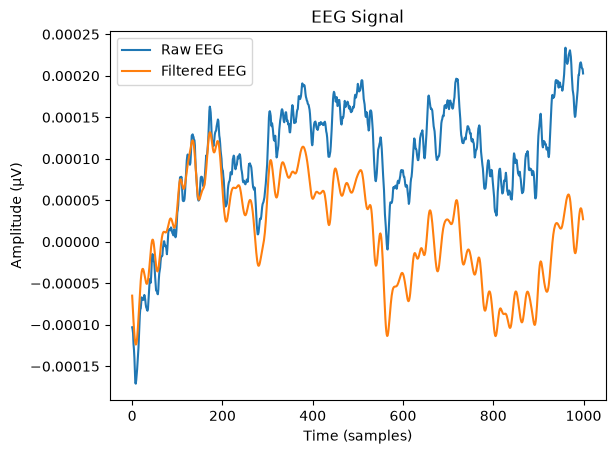

In [19]:
plt.plot(eeg_data[0, :1000], label='Raw EEG')
plt.plot(eeg_filtered[0, :1000], label='Filtered EEG')
plt.xlabel('Time (samples)')
plt.ylabel('Amplitude (µV)')
plt.title('EEG Signal')
plt.legend()
plt.show()

in the next cell, we realigne the seeg data on stimuli onsets

In [12]:
eeg_aligned=[]
for trial in range(len(stimonset_sort)):
    start_idx = int(stimonset_sort[trial,0] + tmin * samp_freq)
    end_idx = int(stimonset_sort[trial,0] + tmax * samp_freq)
    eeg_aligned.append(eeg_filtered[:, start_idx:end_idx])
    
eeg_aligned = np.array(eeg_aligned)

print(eeg_aligned.shape)

times = np.linspace(tmin, tmax, eeg_aligned.shape[2])


(250, 202, 512)


apply a baseline correction, by substracting the mean baseline (from -200 to 0) to all values

In [13]:
# baseline correction
labels=stimonset_sort[:,1]  # Extract labels for each trial

eeg_aligned_corr=eeg_aligned.copy()  # Create a copy of the aligned EEG data for baseline correction
for i,cond in enumerate(np.unique(stimonset_sort[:,1])):
    baseline_mean = np.mean(eeg_aligned_corr[labels==cond][:,:,int((baseline[0]-tmin)*samp_freq):int((baseline[1]-tmin)*samp_freq)], axis=2, keepdims=True)
    eeg_aligned_corr[labels==cond] -= baseline_mean # here we subtract the baseline mean from each trial for the given condition

we will compute the average ERP for one contact , and then we will plot them.


In [14]:
import matplotlib.pyplot as plt 

def plot_erp_one_channel(eeg_aligned,  liste_contacts, stimonset_sort, channel_to_plot):

    # channel_to_plot = "B'2"   # ← modifier ici (hippocampe selon le docx)
    labels=stimonset_sort[:,1]  # Extract labels for each trial
    times = np.linspace(tmin, tmax, eeg_aligned.shape[2])
    # Condition "frequent" : Stimulus/S 78
    # Condition "rare_noncible" : Stimulus/S 68
    # Condition "rare_cible" : Stimulus/S 58

        
    labels_to_plot = ['rare_cible', 'rare_noncible', 'frequent']  # Utiliser les labels tels quels pour le tracé
    colors = ['r', 'g', 'b']  # Couleurs pour chaque condition
    print(np.unique(stimonset_sort[:,1]))

    fig, ax = plt.subplots(figsize=(3,3))

    for i,cond in enumerate(np.unique(stimonset_sort[:,1])):
        ax.plot(times, np.mean(eeg_aligned[labels==cond], axis=0)[liste_contacts.index(channel_to_plot),:],
                color=colors[i],label=labels_to_plot[i])
        
        ax.fill_between(times,
                        np.mean(eeg_aligned[labels==cond], axis=0)[liste_contacts.index(channel_to_plot),:] - np.std(eeg_aligned_corr[labels==cond]/np.sqrt(len(eeg_aligned_corr[labels==cond])), axis=0)[liste_contacts.index(channel_to_plot),:],
                        np.mean(eeg_aligned[labels==cond], axis=0)[liste_contacts.index(channel_to_plot),:] + np.std(eeg_aligned_corr[labels==cond]/np.sqrt(len(eeg_aligned_corr[labels==cond])), axis=0)[liste_contacts.index(channel_to_plot),:],
                        color=colors[i], alpha=0.2)
    ax.set_title(f'ERP for channel {channel_to_plot}', fontsize=12)
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Amplitude (µV)')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.legend(loc='best',fontsize=8)
    ax.axvline(0, color='k', linestyle='--', label='Stimulus')
    



[58 68 78]
[58 68 78]


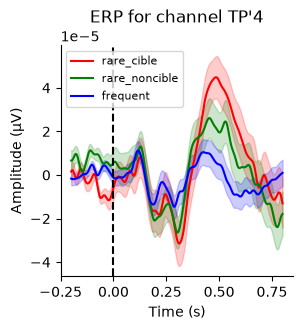

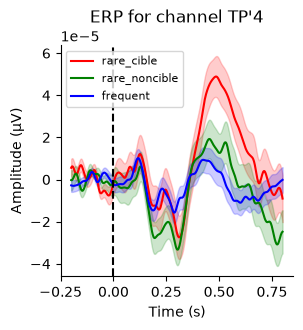

In [20]:
plot_erp_one_channel(eeg_aligned,  liste_contacts, stimonset_sort, "TP'4")
plot_erp_one_channel(eeg_aligned_corr,  liste_contacts, stimonset_sort, "TP'4")

Number of subplots: 202, arranged in a grid of 15x15


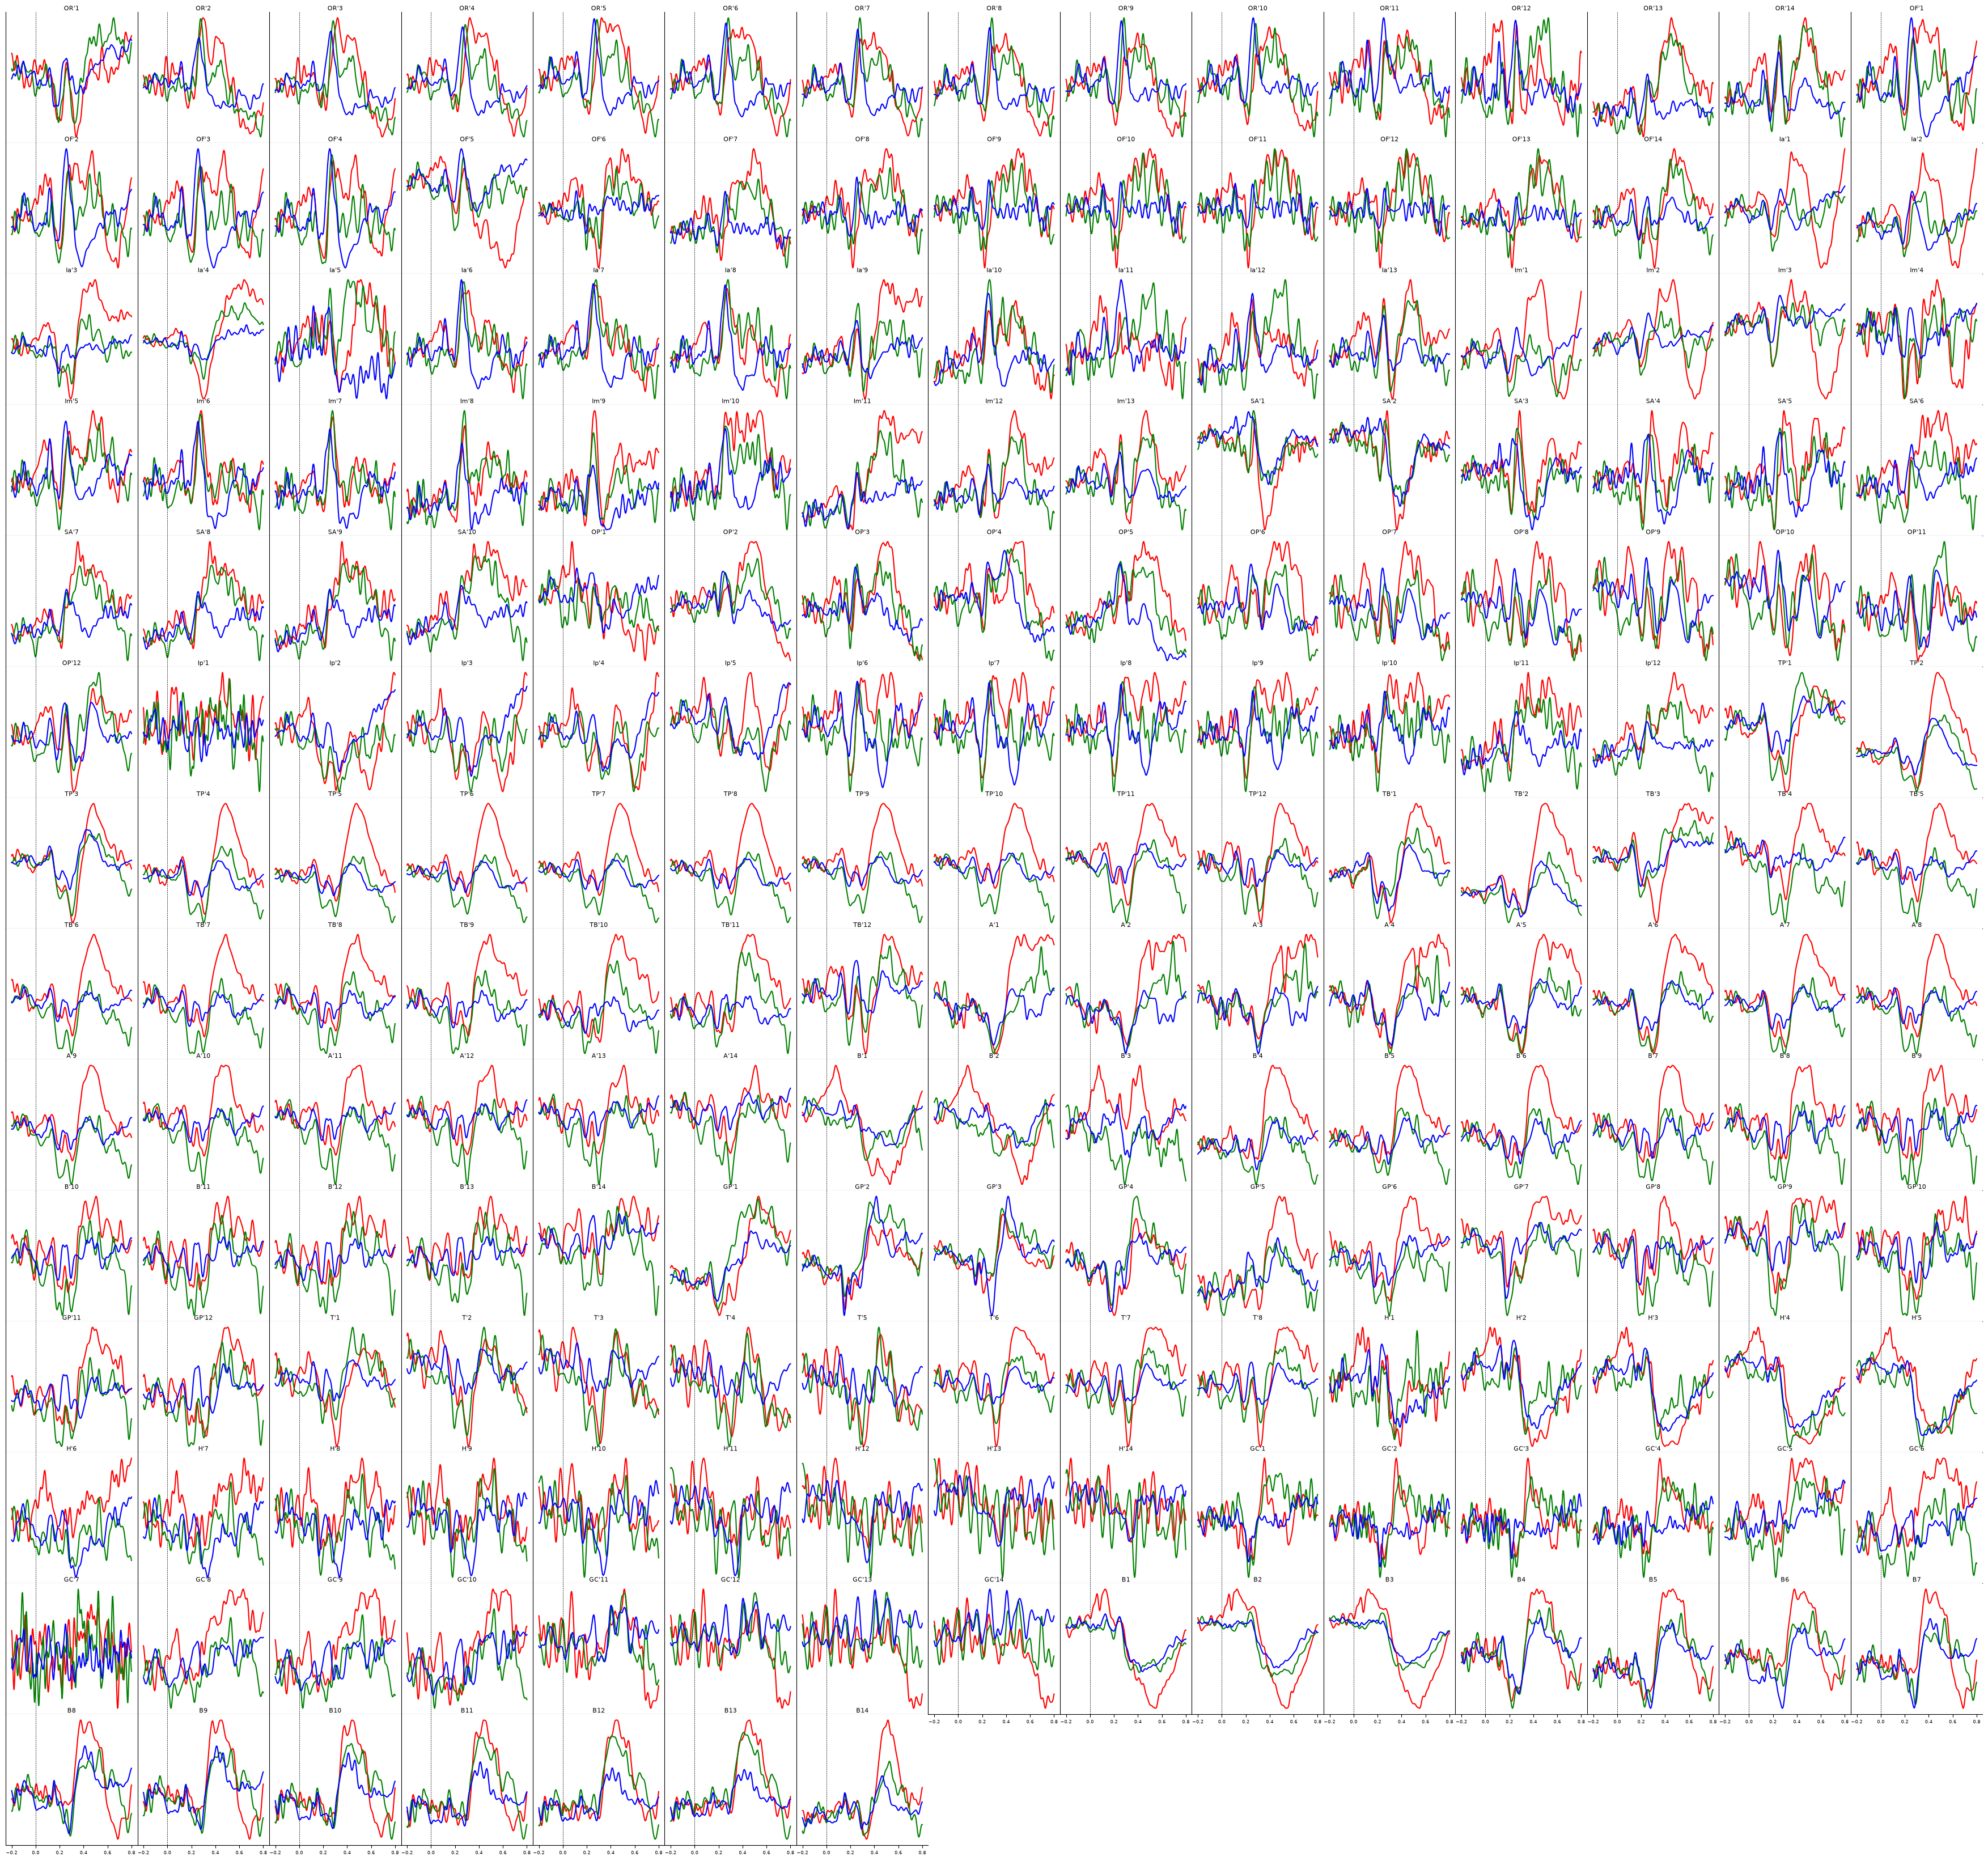

In [16]:

colors = ['r', 'g', 'b']  # Couleurs pour chaque condition
nsub=len(liste_contacts)
sqrt_nsub = int(np.ceil(np.sqrt(nsub)))
print(f"Number of subplots: {nsub}, arranged in a grid of {sqrt_nsub}x{sqrt_nsub}")

fig, ax = plt.subplots(sqrt_nsub, sqrt_nsub, figsize=(3*sqrt_nsub, 3*sqrt_nsub))
fig.subplots_adjust(hspace=0, wspace=0)

for ichannel, channel in enumerate(liste_contacts):
    row = ichannel // sqrt_nsub
    col = ichannel % sqrt_nsub
    for i,cond in enumerate(np.unique(stimonset_sort[:,1])):
        ax[row, col].plot(times, np.mean(eeg_aligned_corr[labels==cond], axis=0)[ichannel,:],
                 color=colors[i])
        
    ax[row, col].set_title(f'{channel}', fontsize=8, pad=2)
    ax[row, col].axvline(0, color='k', linestyle='--', linewidth=0.5)
    ax[row, col].spines['top'].set_visible(False)
    ax[row, col].spines['right'].set_visible(False)
    # Pas de valeurs sur l'axe y
    ax[row, col].set_yticks([])

    # Valeurs x uniquement si pas de channel en-dessous (rang du bas)
    if ichannel + sqrt_nsub >= len(liste_contacts):
        ax[row, col].tick_params(axis='x', labelsize=6)
    else:
        ax[row, col].set_xticks([])

for ichannel in range(len(liste_contacts), sqrt_nsub * sqrt_nsub):
    row = ichannel // sqrt_nsub
    col = ichannel % sqrt_nsub
    ax[row, col].set_visible(False)

find statistical tests to compare the ERP responses between conditions (e.g., frequent vs. rare_cible) for each channel. You can use paired tests. Make sure to correct for multiple comparisons if you are testing multiple channels.


(306, 511)
t-test between rare_cible and frequent: t=-4.293, p=0.000
t-test between rare_cible and rare_noncible: t=-2.932, p=0.004
t-test between frequent and rare_noncible: t=0.938, p=0.349
[58 68 78]


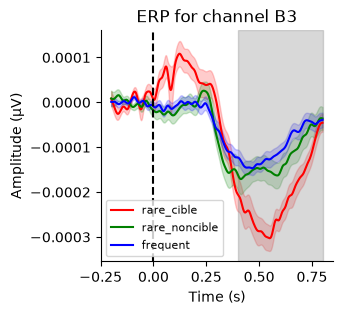

In [21]:
# 200 ms ---   800 ms
# onset at 0 ms sample int(200*512/1000) = 102

from scipy.stats import ttest_ind, ttest_rel

channel_to_test="B3"  # ← modify here ( according to the liste_contacts)

# define the time window for statistical analysis
winonsettime=400   # from stim onset in ms
sizewin=400  # in ms

winoffsettime=winonsettime+sizewin  # in ms after winonsettime

statwin=(int(winonsettime*512/1000)+102,int(winoffsettime*512/1000)+102)  # 200 ms to 800 ms

print(statwin)


labels = ['rare_cible', 'rare_noncible', 'frequent']  # Utiliser les labels tels quels pour le tracé
cond=np.unique(stimonset_sort[:,1])  # Assuming 'frequent' is the third unique label


eeg_freq=eeg_aligned_corr[stimonset_sort[:,1]==cond[2],liste_contacts.index(channel_to_test),:]
eeg_rare_cible=eeg_aligned_corr[stimonset_sort[:,1]==cond[0],liste_contacts.index(channel_to_test),:]
eeg_rare_noncible=eeg_aligned_corr[stimonset_sort[:,1]==cond[1],liste_contacts.index(channel_to_test),:]

t,p=ttest_ind(eeg_rare_cible[:,statwin[0]:statwin[1]].mean(axis=1),eeg_freq[:,statwin[0]:statwin[1]].mean(axis=1))
print(f"t-test between rare_cible and frequent: t={t:.3f}, p={p:.3f}")

t,p=ttest_ind(eeg_rare_cible[:,statwin[0]:statwin[1]].mean(axis=1),eeg_rare_noncible[:,statwin[0]:statwin[1]].mean(axis=1))
print(f"t-test between rare_cible and rare_noncible: t={t:.3f}, p={p:.3f}")

t,p=ttest_ind(eeg_freq[:,statwin[0]:statwin[1]].mean(axis=1),eeg_rare_noncible[:,statwin[0]:statwin[1]].mean(axis=1))
print(f"t-test between frequent and rare_noncible: t={t:.3f}, p={p:.3f}")


#####  PLOT ERP FOR ONE CHANNEL WITH STATISTICAL WINDOW

# channel_to_plot = "B'2"   # ← modifier ici (hippocampe selon le docx)
labels=stimonset_sort[:,1]  # Extract labels for each trial
times = np.linspace(tmin, tmax, eeg_aligned.shape[2])
# Condition "frequent" : Stimulus/S 78
# Condition "rare_noncible" : Stimulus/S 68
# Condition "rare_cible" : Stimulus/S 58

    
labels_to_plot = ['rare_cible', 'rare_noncible', 'frequent']  # Utiliser les labels tels quels pour le tracé
colors = ['r', 'g', 'b']  # Couleurs pour chaque condition
print(np.unique(stimonset_sort[:,1]))

fig, ax = plt.subplots(figsize=(3,3))

for i,cond in enumerate(np.unique(stimonset_sort[:,1])):
    ax.plot(times, np.mean(eeg_aligned_corr[labels==cond], axis=0)[liste_contacts.index(channel_to_test),:],
            color=colors[i],label=labels_to_plot[i])
    
    ax.fill_between(times,
                    np.mean(eeg_aligned_corr[labels==cond], axis=0)[liste_contacts.index(channel_to_test),:] - np.std(eeg_aligned_corr[labels==cond]/np.sqrt(len(eeg_aligned_corr[labels==cond])), axis=0)[liste_contacts.index(channel_to_test),:],
                    np.mean(eeg_aligned_corr[labels==cond], axis=0)[liste_contacts.index(channel_to_test),:] + np.std(eeg_aligned_corr[labels==cond]/np.sqrt(len(eeg_aligned_corr[labels==cond])), axis=0)[liste_contacts.index(channel_to_test),:],
                    color=colors[i], alpha=0.2)
ax.set_title(f'ERP for channel {channel_to_test}', fontsize=12)
ax.set_xlabel('Time (s)')
ax.set_ylabel('Amplitude (µV)')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(loc='best',fontsize=8)
ax.axvline(0, color='k', linestyle='--', label='Stimulus')
ax.axvspan(winonsettime/1000, winoffsettime/1000, color='gray', alpha=0.3, label='Statistical Window')


power spectrum analysis

PSD representation for some selected channels (e.g., B3, B4, B5) for each condition (frequent, rare_noncible, rare_cible). The power spectral density (PSD) can be computed using the Welch method (`scipy.signal.welch` function for this purpose)or similar techniques.

(202, 270432)
(270432,)
(270432,)


C:\Users\Nicolas Catz\AppData\Local\Temp\ipykernel_5388\2559969148.py:30: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs.legend(loc='upper right', fontsize=8)


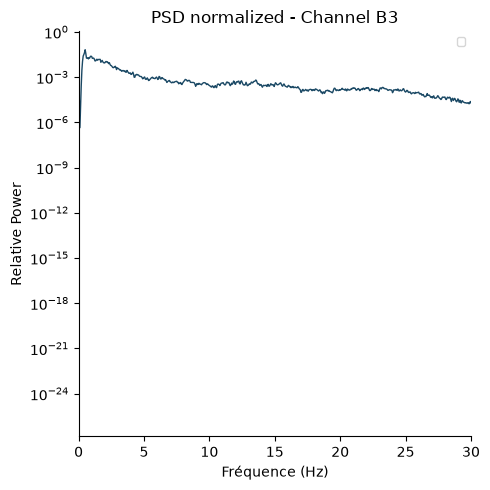

In [18]:
from scipy.signal import welch
channel_to_plot = "B3"  # ← modify here ( according to the liste_contacts)

eeg_win=eeg_filtered
print(eeg_win.shape)
print(eeg_win[liste_contacts.index("B3"),:].shape)
eeg_psd=eeg_filtered[liste_contacts.index("B3"),:]
print(eeg_psd.shape)


psd_band = (0.3,30)    # band used for normalization (corresponds to the band-pass filter)

fig, axs = plt.subplots(1,1, figsize=(5,5))

freqs, psd = welch(eeg_psd, fs=samp_freq, nperseg=samp_freq * 20)

# normalisation : puissance relative (la PSD de chaque canal somme à 1 sur 4-40 Hz)
norm_mask = (freqs >= psd_band[0]) & (freqs <= psd_band[1])
psd_norm = psd / psd[norm_mask].sum()

axs.plot(freqs, psd_norm, color='#1B4965', linewidth=1)
axs.set_title(f'PSD normalized - Channel {channel_to_plot}')
axs.set_yscale('log')
axs.set_ylabel('Relative Power')
axs.spines['top'].set_visible(False)
axs.spines['right'].set_visible(False)
axs.set_xlim([0, 30])  # Limiting the x-axis to 0-40 Hz


axs.legend(loc='upper right', fontsize=8)
axs.set_xlabel('Fréquence (Hz)')

plt.tight_layout()
plt.show()
